A customer service centre receives calls. The probability that a call results in a successful resolution is 0.25. Assume that each call is independent and the probability of success remains constant.

Let \(X\) be the number of calls required to obtain the first successful resolution, including the successful call.

Write a Python program to:

(a) Identify the distribution, its parameter and possible values of \(X\).

(b) Simulate 20,000 experiments and calculate the empirical PMF.

(c) Calculate the theoretical PMF and display the empirical and theoretical values in a table.

(d) Plot the empirical and theoretical PMFs.

(e) Calculate the empirical and theoretical expectation and variance.

(f) Calculate the probability that more than three calls are required to obtain the first successful resolution, both empirically and theoretically.

Distribution: Geometric
Probability of success: 0.25
Probability of failure: 0.75
Possible values: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]

Empirical vs Theoretical PMF:
 x  Empirical PMF  Theoretical PMF
 1         0.2490           0.2500
 2         0.1891           0.1875
 3         0.1427           0.1406
 4         0.1072           0.1055
 5         0.0774           0.0791
 6         0.0574           0.0593
 7         0.0448           0.0445
 8         0.0330           0.0334
 9         0.0236           0.0250
10         0.0199           0.0188
11         0.0142           0.0141
12         0.0112           0.0106
13         0.0063           0.0079
14         0.0054           0.0059
15         0.0055           0.0045


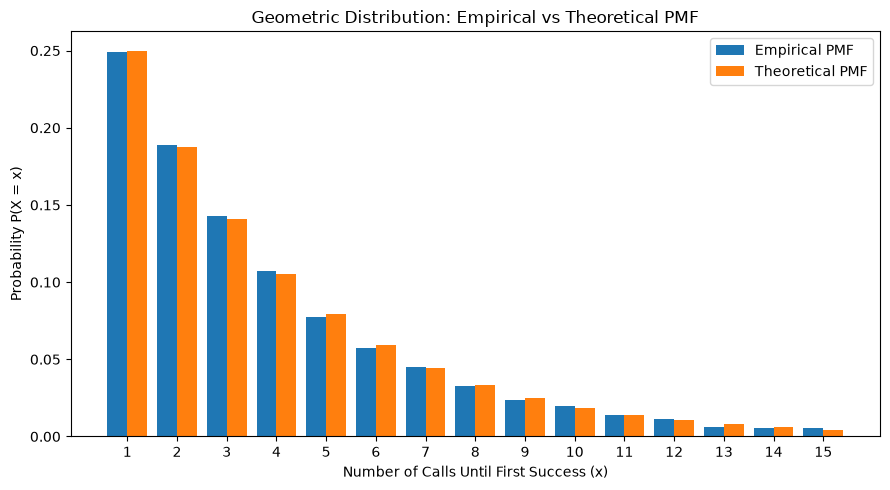


Expectation and Variance:
        Empirical  Theoretical
E[X]       3.9894          4.0
Var(X)    12.0156         12.0

Probability P(X > 3):
Simulated probability = 0.4192
Theoretical probability = 0.4219


In [1]:

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Given parameters
p = 0.25
M = 20000

# (a) Identify distribution
print("Distribution: Geometric")
print("Probability of success:", p)
print("Probability of failure:", 1 - p)

# (b) Simulate the number of trials until first success
rng = np.random.default_rng(42)
X = rng.geometric(p, size=M)

# Possible values for displaying the PMF
x = np.arange(1, 16)
print("Possible values:", x)

# (c) Calculate empirical and theoretical PMF
emp = np.array([(X == k).mean() for k in x])
theo = stats.geom.pmf(x, p)

pmf_table = pd.DataFrame({
    "x": x,
    "Empirical PMF": emp,
    "Theoretical PMF": theo
})

print("\nEmpirical vs Theoretical PMF:")
print(pmf_table.round(4).to_string(index=False))

# (d) Plot both PMFs
plt.figure(figsize=(9, 5))

plt.bar(x - 0.2, emp, width=0.4, label="Empirical PMF")
plt.bar(x + 0.2, theo, width=0.4, label="Theoretical PMF")

plt.xlabel("Number of Calls Until First Success (x)")
plt.ylabel("Probability P(X = x)")
plt.title("Geometric Distribution: Empirical vs Theoretical PMF")
plt.xticks(x)
plt.legend()
plt.tight_layout()
plt.show()

# (e) Calculate expectation and variance
emp_mean = X.mean()
theo_mean = 1 / p

emp_var = X.var()
theo_var = (1 - p) / (p ** 2)

statistics_table = pd.DataFrame({
    "Empirical": [emp_mean, emp_var],
    "Theoretical": [theo_mean, theo_var]
}, index=["E[X]", "Var(X)"])

print("\nExpectation and Variance:")
print(statistics_table.round(4))

# (f) Calculate P(X > 3)
p_sim = (X > 3).mean()
p_theory = stats.geom.sf(3, p)

print("\nProbability P(X > 3):")
print(f"Simulated probability = {p_sim:.4f}")
print(f"Theoretical probability = {p_theory:.4f}")
